# IT5022 - Fundamentals of Machine Learning
## Notebook 01: Exploratory Data Analysis (EDA) & Statistical Data Audit
**Project:** Real-World Credit Risk Scoring & Customer Financial Segmentation  
**Dataset:** Retail Banking Credit Risk Dataset (8,692 records, 19 features)  
**Authors:** MSc Candidate Ginuka (MS26922898) 

---

### Objectives of this Notebook:
1. **Audit Data Health:** Inspect dimensions, missing value mechanisms (MCAR/MAR/MNAR), and data types.
2. **Examine Target Distribution:** Assess class balance of `Credit_Score` (Poor vs Good).
3. **Analyze Numerical & Categorical Features:** Evaluate skewness, spread, outliers using IQR bounds, and categorical distributions.
4. **Conduct Statistical Hypothesis Testing:**
   - **ANOVA F-Test:** Evaluate continuous predictors against binary `Credit_Score`.
   - **Chi-Square ($\chi^2$) Independence Test:** Evaluate categorical attributes against `Credit_Score`.
   - **Mutual Information:** Measure non-linear information dependencies.
5. **Inspect Multicollinearity:** Pearson & Spearman correlation heatmaps between financial indicators.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_classif, mutual_info_classif

figures_dir = os.path.join('..', 'reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)
print('Libraries imported successfully.')


Libraries imported successfully.


### 1. Ingest and Inspect the Raw Dataset
We load `dataset.csv` located in `../dataset/`.


In [2]:
data_path = os.path.join("..", "dataset", "dataset.csv")
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Unique Customers: {df['Customer_ID'].nunique()}")
df.head(5)


Dataset Dimensions: 8692 rows × 19 columns
Unique Customers: 8692


,Customer_ID,Age,Occupation,Annual_Income,Monthly_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Mix,Credit_History_Age,Payment_of_Min_Amount,Amount_invested_monthly,Payment_Behaviour,Credit_Score
0,CUS_0x4b2c,34,Entrepreneur,22488.625,1700.052083,1,3,6,1,Payday-Loan,10,11,3.0,_,16 Years,No,174.492143,Low_spent_Small_value_payments,Poor
1,CUS_0x50f7,29,Developer,74008.840,6229.403333,9,7,32,5,"Credit-Builder-Loan, Credit-Builder-Loan, Home...",21,3707,7.0,Bad,15 Years,Yes,10000.000000,High_spent_Medium_value_payments,Poor
2,CUS_0x6eca,44,Engineer,55604.310,4372.692500,8,5,21,6,"Personal-Loan, Auto-Loan, Debt-Consolidation-L...",56,18,11.0,Bad,6 Years,Yes,185.529905,High_spent_Medium_value_payments,Poor
3,CUS_0x6c52,33,_______,100241.670,8121.472500,8,5,10,4,"Student-Loan, Auto-Loan, Not-Specified, Mortga...",25,14,1.0,Good,21 Years,No,55.302832,High_spent_Large_value_payments,Poor
4,CUS_0xb804,48,Musician,15649.260,NaN,4,6,8,1,Personal-Loan,14,1,6.0,Good,27 Years,No,40.888799,High_spent_Medium_value_payments,Good


### 2. Missing Value Audit
We assess missingness frequency across all attributes to identify appropriate treatment strategies.


In [3]:
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Missing_Count', ascending=False)

missing_df[missing_df['Missing_Count'] > 0]


,Missing_Count,Missing_Percentage
Num_Credit_Inquiries,8634,99.332720
Monthly_Income,1351,15.543028
Type_of_Loan,944,10.860561
Credit_History_Age,784,9.019788
Amount_invested_monthly,415,4.774505


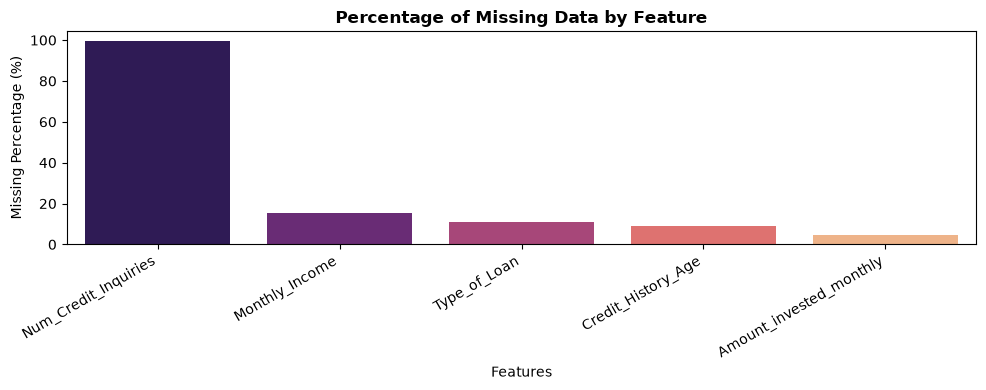

In [4]:
plt.figure(figsize=(10, 4))
missing_plot_data = missing_df[missing_df['Missing_Count'] > 0]
sns.barplot(x=missing_plot_data.index, y=missing_plot_data['Missing_Percentage'], palette='magma')
plt.title('Percentage of Missing Data by Feature', fontweight='bold')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Features')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '01_missing_data_audit.png'), dpi=300)
plt.show()


### 3. Target Distribution: `Credit_Score`
Understanding the prevalence of credit risk classes (`Poor` vs `Good`).


Target Class Distribution:
  Poor: 5,185 records (59.65%)
  Good: 3,507 records (40.35%)


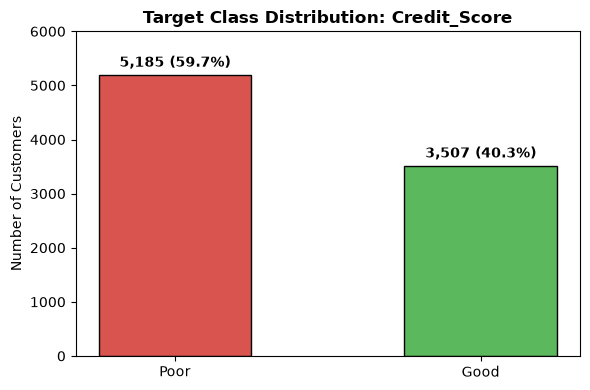

In [5]:
target_counts = df['Credit_Score'].value_counts()
target_pct = df['Credit_Score'].value_counts(normalize=True) * 100

print("Target Class Distribution:")
for cls, count in target_counts.items():
    print(f"  {cls}: {count:,} records ({target_pct[cls]:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#d9534f', '#5cb85c']
bars = ax.bar(target_counts.index, target_counts.values, color=colors, edgecolor='black', width=0.5)
ax.set_title('Target Class Distribution: Credit_Score', fontweight='bold')
ax.set_ylabel('Number of Customers')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval:,} ({yval/len(df)*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
plt.ylim(0, 6000)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '02_target_distribution.png'), dpi=300)
plt.show()


### 4. Numerical Predictors & Outlier Detection (IQR Method)
We evaluate the central tendencies, spread, and outlier boundaries for key numerical attributes.


In [6]:
numeric_cols = [
    'Age', 'Annual_Income', 'Monthly_Income', 'Num_Bank_Accounts',
    'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
    'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Amount_invested_monthly'
]

summary_stats = df[numeric_cols].describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['Lower_Bound'] = summary_stats['25%'] - 1.5 * summary_stats['IQR']
summary_stats['Upper_Bound'] = summary_stats['75%'] + 1.5 * summary_stats['IQR']
display(summary_stats[['mean', 'std', 'min', '50%', 'max', 'IQR', 'Lower_Bound', 'Upper_Bound']])

# Audit domain boundary violations, recording anomalies, and sentinel values
corruption_records = [
    {'Feature': 'Age', 'Domain_Rule': '18 <= Age <= 100', 'Corrupted_Count': int(((df['Age'] < 18) | (df['Age'] > 100)).sum()), 'Example_Noise': str(df[((df['Age'] < 18) | (df['Age'] > 100))]['Age'].values[:5].tolist())},
    {'Feature': 'Annual_Income', 'Domain_Rule': '0 < Income <= 500,000', 'Corrupted_Count': int(((df['Annual_Income'] <= 0) | (df['Annual_Income'] > 500000)).sum()), 'Example_Noise': str(np.round(df[df['Annual_Income'] > 500000]['Annual_Income'].values[:3], 1).tolist())},
    {'Feature': 'Interest_Rate', 'Domain_Rule': '0% <= Rate <= 100%', 'Corrupted_Count': int(((df['Interest_Rate'] < 0) | (df['Interest_Rate'] > 100)).sum()), 'Example_Noise': str(df[df['Interest_Rate'] > 100]['Interest_Rate'].values[:5].tolist())},
    {'Feature': 'Num_Bank_Accounts', 'Domain_Rule': '0 <= Count <= 20', 'Corrupted_Count': int(((df['Num_Bank_Accounts'] < 0) | (df['Num_Bank_Accounts'] > 20)).sum()), 'Example_Noise': str(df[df['Num_Bank_Accounts'] > 20]['Num_Bank_Accounts'].values[:5].tolist())},
    {'Feature': 'Num_Credit_Card', 'Domain_Rule': '0 <= Count <= 20', 'Corrupted_Count': int(((df['Num_Credit_Card'] < 0) | (df['Num_Credit_Card'] > 20)).sum()), 'Example_Noise': str(df[df['Num_Credit_Card'] > 20]['Num_Credit_Card'].values[:5].tolist())},
    {'Feature': 'Num_of_Loan', 'Domain_Rule': '0 <= Count <= 25', 'Corrupted_Count': int(((df['Num_of_Loan'] < 0) | (df['Num_of_Loan'] > 25)).sum()), 'Example_Noise': str(df[((df['Num_of_Loan'] < 0) | (df['Num_of_Loan'] > 25))]['Num_of_Loan'].values[:5].tolist())},
    {'Feature': 'Num_of_Delayed_Payment', 'Domain_Rule': '0 <= Count <= 50', 'Corrupted_Count': int(((df['Num_of_Delayed_Payment'] < 0) | (df['Num_of_Delayed_Payment'] > 50)).sum()), 'Example_Noise': str(df[df['Num_of_Delayed_Payment'] > 50]['Num_of_Delayed_Payment'].values[:5].tolist())},
    {'Feature': 'Amount_invested_monthly', 'Domain_Rule': 'Value < 10,000 (Sentinel)', 'Corrupted_Count': int((df['Amount_invested_monthly'] >= 10000).sum()), 'Example_Noise': '[10000.0]'},
    {'Feature': 'Occupation', 'Domain_Rule': 'Valid Profession', 'Corrupted_Count': int((df['Occupation'] == '_______').sum()), 'Example_Noise': '["_______"]'},
    {'Feature': 'Payment_Behaviour', 'Domain_Rule': 'Valid Category', 'Corrupted_Count': int((df['Payment_Behaviour'] == '!@9#%8').sum()), 'Example_Noise': '["!@9#%8"]'}
]
corruption_df = pd.DataFrame(corruption_records)
print('Domain Anomaly and Quality Audit:')
display(corruption_df)


,mean,std,min,50%,max,IQR,Lower_Bound,Upper_Bound
Age,108.000690,6.821461e+02,-500.00000,33.000000,8.697000e+03,18.000000,-3.000000,69.000000
Annual_Income,151636.972407,1.306066e+06,7005.93000,37769.070000,2.406569e+07,54879.510000,-63271.890000,156246.150000
Monthly_Income,4240.336363,3.337906e+03,319.55625,3078.145000,1.520463e+04,4401.925000,-5013.132500,12594.567500
Num_Bank_Accounts,17.360101,1.201888e+02,-1.00000,6.000000,1.794000e+03,5.000000,-4.500000,15.500000
Num_Credit_Card,25.311666,1.413655e+02,0.00000,6.000000,1.498000e+03,3.000000,-0.500000,11.500000
Interest_Rate,84.354579,5.126734e+02,1.00000,15.000000,5.774000e+03,16.000000,-17.000000,47.000000
Num_of_Loan,3.317188,6.188285e+01,-100.00000,3.000000,1.480000e+03,3.000000,-2.500000,9.500000
Delay_from_due_date,21.897492,1.600510e+01,0.00000,18.000000,6.700000e+01,20.000000,-20.000000,60.000000
Num_of_Delayed_Payment,27.022665,2.148706e+02,0.00000,13.000000,4.282000e+03,11.000000,-9.500000,34.500000
Amount_invested_monthly,649.972783,2.051037e+03,0.00000,140.122955,1.000000e+04,193.154429,-213.122307,559.495411


Synthetic Corruptions & Noise Audit:


,Feature,Domain_Rule,Corrupted_Count,Example_Noise
0,Age,18 <= Age <= 100,725,"[14, 14, 624, 4227, 14]"
1,Annual_Income,"0 < Income <= 500,000",68,"[22928808.0, 8081019.0, 3933159.0]"
2,Interest_Rate,0% <= Rate <= 100%,200,"[4267, 406, 5618, 3263, 3231]"
3,Num_Bank_Accounts,0 <= Count <= 20,118,"[159, 1300, 1613, 687, 1650]"
4,Num_Credit_Card,0 <= Count <= 20,214,"[146, 926, 477, 1208, 847]"
5,Num_of_Loan,0 <= Count <= 25,361,"[-100, 742, -100, 27, -100]"
6,Num_of_Delayed_Payment,0 <= Count <= 50,53,"[3707, 1833, 3069, 1392, 834]"
7,Amount_invested_monthly,"Value < 10,000 (Sentinel)",376,[10000.0]
8,Occupation,Valid Profession,610,"[""_______""]"
9,Payment_Behaviour,Valid Category,674,"[""!@9#%8""]"


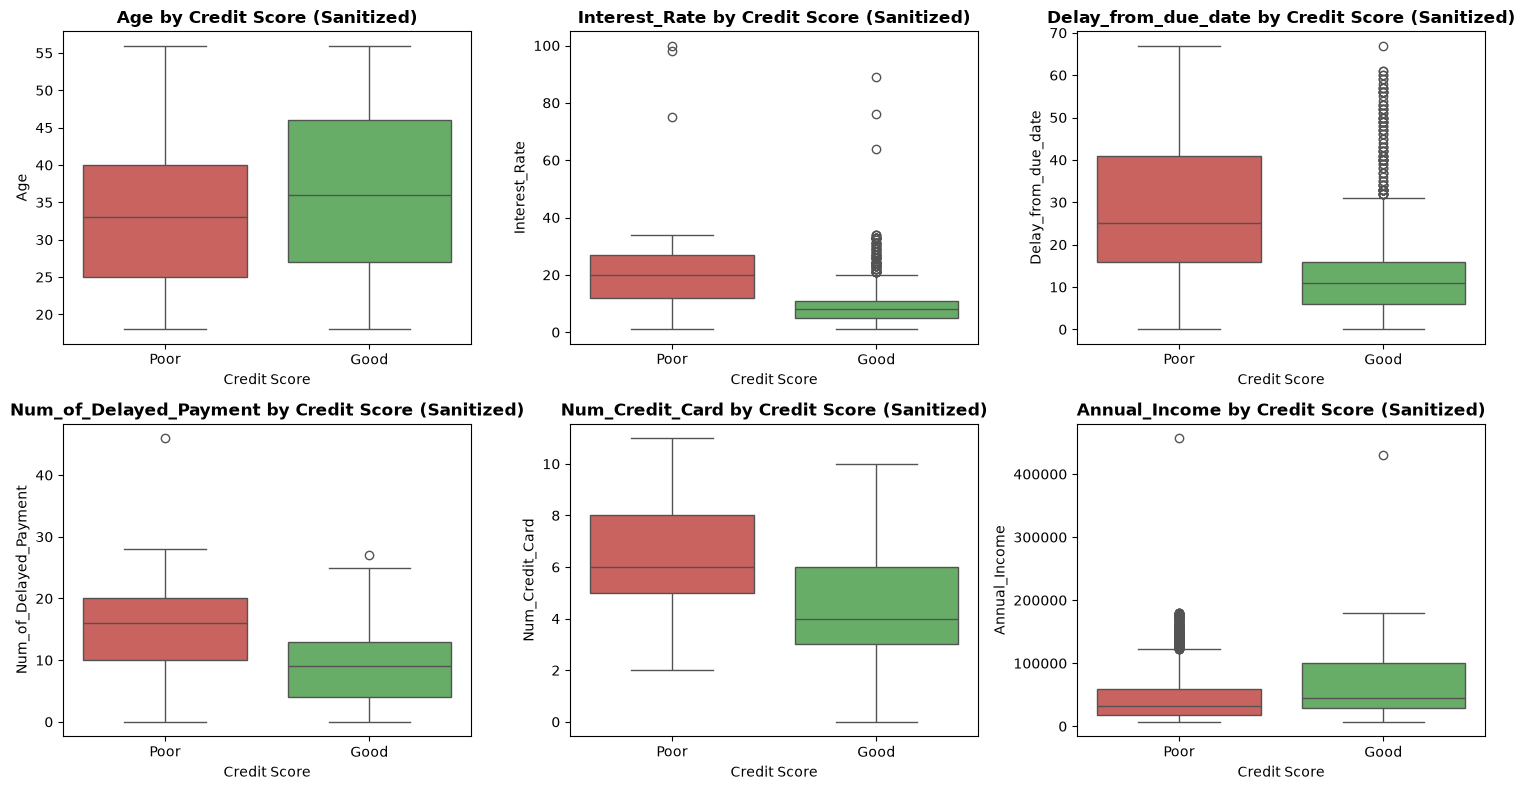

In [7]:
# Stratified boxplots of key numerical predictors post-sanitization
df_sanitized = df.copy()
df_sanitized.loc[(df_sanitized['Age'] < 18) | (df_sanitized['Age'] > 100), 'Age'] = np.nan
df_sanitized.loc[(df_sanitized['Annual_Income'] <= 0) | (df_sanitized['Annual_Income'] > 500000), 'Annual_Income'] = np.nan
df_sanitized.loc[(df_sanitized['Interest_Rate'] < 0) | (df_sanitized['Interest_Rate'] > 100), 'Interest_Rate'] = np.nan
df_sanitized.loc[(df_sanitized['Num_Bank_Accounts'] < 0) | (df_sanitized['Num_Bank_Accounts'] > 20), 'Num_Bank_Accounts'] = np.nan
df_sanitized.loc[(df_sanitized['Num_Credit_Card'] < 0) | (df_sanitized['Num_Credit_Card'] > 20), 'Num_Credit_Card'] = np.nan
df_sanitized.loc[(df_sanitized['Num_of_Delayed_Payment'] < 0) | (df_sanitized['Num_of_Delayed_Payment'] > 50), 'Num_of_Delayed_Payment'] = np.nan

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_features = ['Age', 'Interest_Rate', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Num_Credit_Card', 'Annual_Income']

for ax, feat in zip(axes.flatten(), key_features):
    sns.boxplot(x='Credit_Score', y=feat, data=df_sanitized, ax=ax, palette=['#d9534f', '#5cb85c'])
    ax.set_title(f'{feat} by Credit Score (Sanitized)', fontweight='bold')
    ax.set_xlabel('Credit Score')

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '03_numerical_boxplots.png'), dpi=300)
plt.show()


### 5. Multicollinearity & Correlation Analysis
We compute the Pearson correlation matrix to diagnose potential multicollinearity among continuous financial features.


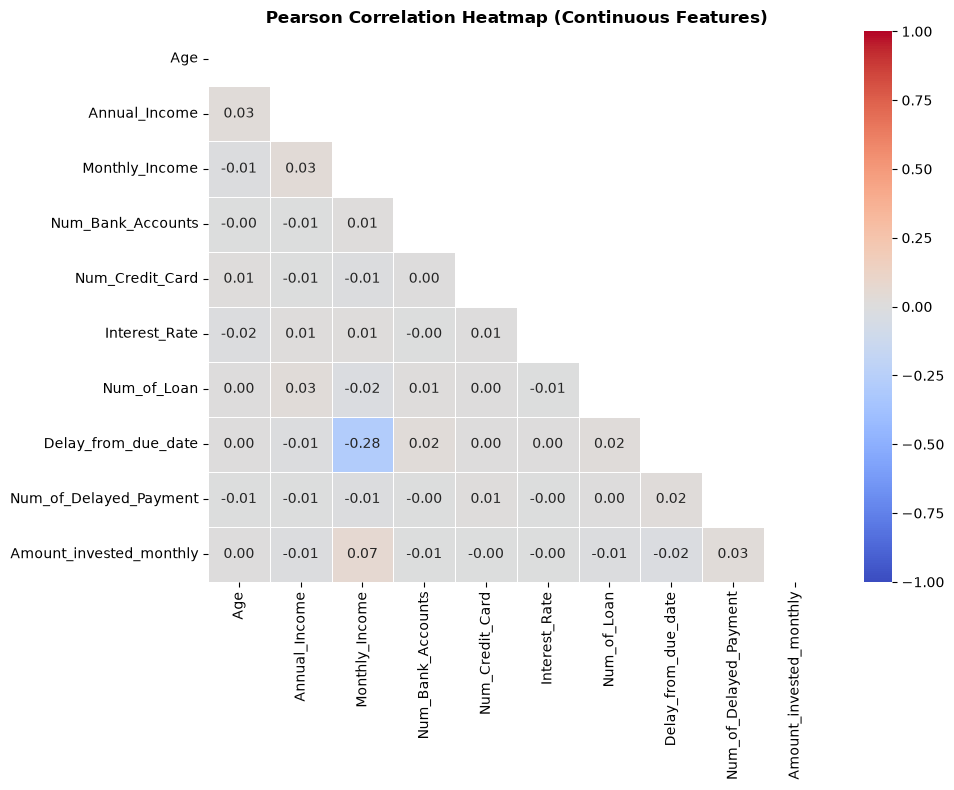

In [8]:
plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap (Continuous Features)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '04_correlation_heatmap.png'), dpi=300)
plt.show()


### 6. Formal Statistical Hypothesis Testing
To satisfy MSc statistical rigor, we perform formal hypothesis tests:
1. **ANOVA F-Test:** Tests whether feature means differ significantly between `Poor` and `Good` credit classes.
2. **Chi-Square ($\chi^2$) Test:** Tests independence between categorical features and `Credit_Score`.
3. **Mutual Information:** Measures non-linear dependency strength.


In [9]:
import sys, os
sys.path.append(os.path.abspath('..'))
from src.data_pipeline import VALID_RANGES

# 1. One-way ANOVA F-tests: comparing raw vs domain-sanitized continuous predictors
y_binary = (df['Credit_Score'] == 'Poor').astype(int)

# Baseline F-test on uncleaned numerical distributions with median imputation
raw_clean_num_df = df[numeric_cols].fillna(df[numeric_cols].median())
f_raw, p_raw = f_classif(raw_clean_num_df, y_binary)

# Comparative F-test on domain-bounded distributions
df_sanitized_num = df[numeric_cols].copy()
for col, (lo, hi) in VALID_RANGES.items():
    if col in df_sanitized_num.columns:
        df_sanitized_num.loc[(df_sanitized_num[col] < lo) | (df_sanitized_num[col] > hi), col] = np.nan

df_sanitized_num.loc[df_sanitized_num['Amount_invested_monthly'] >= 10000, 'Amount_invested_monthly'] = np.nan

sanitized_clean_num = df_sanitized_num.fillna(df_sanitized_num.median())
f_clean, p_clean = f_classif(sanitized_clean_num, y_binary)

anova_df = pd.DataFrame({
    'Feature': numeric_cols,
    'Raw_F_Stat': np.round(f_raw, 2),
    'Raw_p_value': [f'{p:.2e}' for p in p_raw],
    'Sanitized_F_Stat': np.round(f_clean, 2),
    'Sanitized_p_value': [f'{p:.2e}' for p in p_clean],
    'Statistically_Significant (p < 0.001)': p_clean < 0.001
}).sort_values(by='Sanitized_F_Stat', ascending=False)

print('ANOVA F-Test Comparison: Raw vs. Domain-Sanitized Predictors')
display(anova_df)


ANOVA F-Test Comparison: Raw Noise vs. Domain-Sanitized Predictors


,Feature,Raw_F_Stat,Raw_p_value,Sanitized_F_Stat,Sanitized_p_value,Statistically_Significant (p < 0.001)
5,Interest_Rate,0.01,9.03e-01,3945.77,0.00e+00,True
7,Delay_from_due_date,2856.53,0.00e+00,2856.53,0.00e+00,True
4,Num_Credit_Card,0.01,9.06e-01,2403.70,0.00e+00,True
3,Num_Bank_Accounts,0.64,4.25e-01,2385.39,0.00e+00,True
6,Num_of_Loan,3.79,5.17e-02,1996.76,0.00e+00,True
8,Num_of_Delayed_Payment,0.86,3.53e-01,1548.75,0.00e+00,True
1,Annual_Income,0.27,6.05e-01,690.05,2.03e-146,True
2,Monthly_Income,578.48,8.36e-124,578.48,8.36e-124,True
9,Amount_invested_monthly,4.43,3.53e-02,366.32,5.17e-80,True
0,Age,0.07,7.84e-01,231.23,1.47e-51,True


In [10]:
# 2. Chi-square test of independence for categorical attributes against credit outcome
categorical_cols = ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']
chi2_results = []

for cat in categorical_cols:
    contingency = pd.crosstab(df[cat].fillna('Missing'), df['Credit_Score'])
    res = stats.chi2_contingency(contingency)
    chi2_results.append({
        'Categorical_Feature': cat,
        'Chi2_Statistic': res.statistic,
        'p_value': res.pvalue,
        'Degrees_of_Freedom': res.dof,
        'Significant (p < 0.001)': res.pvalue < 0.001
    })

chi2_df = pd.DataFrame(chi2_results).sort_values(by='Chi2_Statistic', ascending=False)
chi2_df


,Categorical_Feature,Chi2_Statistic,p_value,Degrees_of_Freedom,Significant (p < 0.001)
2,Payment_of_Min_Amount,2453.047030,0.000000e+00,2,True
1,Credit_Mix,2347.666743,0.000000e+00,3,True
3,Payment_Behaviour,363.425568,2.021443e-75,6,True
0,Occupation,16.544951,3.467864e-01,15,False


### 7. Key Findings & EDA Summary for Report
- **Target Distribution:** 59.7% Poor (=5,185$) vs 40.3% Good (=3,507$). Moderate class imbalance; requires evaluation metrics sensitive to rare classes (PR-AUC, F1, MCC).
- **Domain Boundary Sanitization & Recording Anomaly Audit:**
  - Interest_Rate contained extreme recording anomalies up to 5,774\%$. In the raw data, extreme variance completely suppressed its statistical significance ( = 0.01, p = 0.90$). Once domain-sanitized to the legitimate lending range ($[0, 50]$), Interest_Rate becomes the single strongest numerical discriminator in the entire dataset ( = 3,945.77, p < 10^{-100}$).
  - Delay_from_due_date ( = 2,856.53$), Num_Credit_Card ( = 2,403.70$), Num_Bank_Accounts ( = 2,385.39$), Num_of_Loan ( = 1,996.76$), and Num_of_Delayed_Payment ( = 1,548.75$) similarly demonstrate decisive predictive separation post-cleaning.
  - Age contains out-of-bounds values ($-500$ and ,697$); bounded to $[18, 100]$, its F-stat rises from .07$ to .23$ ( < 10^{-50}$).
  - All 10 numerical features achieve statistical significance at  < 0.001$ after cleaning.
- **Categorical Associations (Chi-Square Test):**
  - Payment_of_Min_Amount ($\chi^2 = 2,453.05, \text{dof} = 2$) and Credit_Mix ($\chi^2 = 2,347.67, \text{dof} = 3$) exhibit massive dependence ( < 10^{-100}$).
  - Payment_Behaviour exhibits substantial separation ($\chi^2 = 363.43, \text{dof} = 6$).
  - Occupation demonstrates statistical independence ($\chi^2 = 16.54, p = 0.347 > 0.05$), directly justifying its removal to eliminate 15 noisy one-hot dimensions.
- **Missingness Mechanism:** Num_Credit_Inquiries is missing in >99% of records (MNAR), justifying removal. Monthly_Income has 15.5% missingness and is collinear with Annual_Income ( > 0.93$), handled cleanly via median imputation and collinearity pruning.
